# 06 — Final pipeline and summary of all models

Rubric item: *Your pipeline*. Compares every evaluated run on one protocol and records the submission. Tables fill from `results/eval/*.json`; the submission log is `SUBMISSIONS.md`.

In [1]:
import json, sys
from pathlib import Path
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from common import CLASS_NAMES

def show(name, width=900, folder="images"):
    display(Image(filename=str(ROOT / folder / name), width=width))

def table(rows, header):
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)] + ["| " + " | ".join(map(str, r)) + " |" for r in rows]
    display(Markdown("\n".join(lines)))

def load(path):
    p = ROOT / path
    return json.loads(p.read_text()) if p.is_file() else None

f3 = lambda v: "n/a" if v is None else f"{v:.3f}"

## Every evaluated run

In [2]:
rows = []
for path in sorted((ROOT / "results" / "eval").glob("*.json")):
    r = json.loads(path.read_text())
    rows.append([r["name"], r["family"], f3(r["AP"]), f3(r["AP50"]), f3(r["AP_small"]), f3(r["AP_medium"]), f3(r["AP_large"]), f'{r["ms_per_frame"]:.0f}'])
table(rows, ["run", "family", "AP", "AP50", "AP small", "AP medium", "AP large", "ms per frame"])

| run | family | AP | AP50 | AP small | AP medium | AP large | ms per frame |
|---|---|---|---|---|---|---|---|
| ens-3models | ensemble | 0.249 | 0.480 | 0.106 | 0.207 | 0.443 | 207 |
| ens-5models | ensemble | 0.255 | 0.484 | 0.106 | 0.215 | 0.451 | 330 |
| ens-rtdetr2 | ensemble | 0.241 | 0.466 | 0.105 | 0.204 | 0.424 | 76 |
| frcnn-base | fasterrcnn | 0.170 | 0.362 | 0.066 | 0.155 | 0.327 | 131 |
| frcnn-roi128 | fasterrcnn | 0.151 | 0.328 | 0.063 | 0.137 | 0.303 | 110 |
| frcnn-rpn300 | fasterrcnn | 0.137 | 0.289 | 0.061 | 0.137 | 0.273 | 109 |
| nb-fasterrcnn | fasterrcnn | 0.140 | 0.314 | 0.061 | 0.139 | 0.259 | 130 |
| nb-retinanet | retinanet | 0.103 | 0.195 | 0.041 | 0.098 | 0.204 | 110 |
| nb-rtdetr | rtdetr | 0.225 | 0.426 | 0.086 | 0.188 | 0.416 | 38 |
| nb-yolo | yolo | 0.131 | 0.254 | 0.041 | 0.102 | 0.273 | 11 |
| retina-anchors16 | retinanet | 0.148 | 0.324 | 0.049 | 0.138 | 0.272 | 96 |
| retina-base | retinanet | 0.151 | 0.305 | 0.047 | 0.141 | 0.279 | 96 |
| retina-giou | retinanet | 0.158 | 0.313 | 0.055 | 0.143 | 0.310 | 111 |
| rtdetr-l-e6-infer800 | rtdetr | 0.221 | 0.429 | 0.105 | 0.201 | 0.376 | 52 |
| rtdetr-l-e6-infer960 | rtdetr | 0.223 | 0.434 | 0.116 | 0.202 | 0.360 | 67 |
| rtdetr-l-e6 | rtdetr | 0.223 | 0.429 | 0.106 | 0.192 | 0.388 | 38 |
| rtdetr-l-masked | rtdetr | 0.217 | 0.413 | 0.098 | 0.190 | 0.381 | 44 |
| yolo26n-base | yolo | 0.128 | 0.243 | 0.040 | 0.100 | 0.273 | 13 |
| yolo26n-box10 | yolo | 0.108 | 0.218 | 0.038 | 0.098 | 0.220 | 13 |
| yolo26n-hires960 | yolo | 0.162 | 0.308 | 0.062 | 0.136 | 0.332 | 12 |

## Side by side

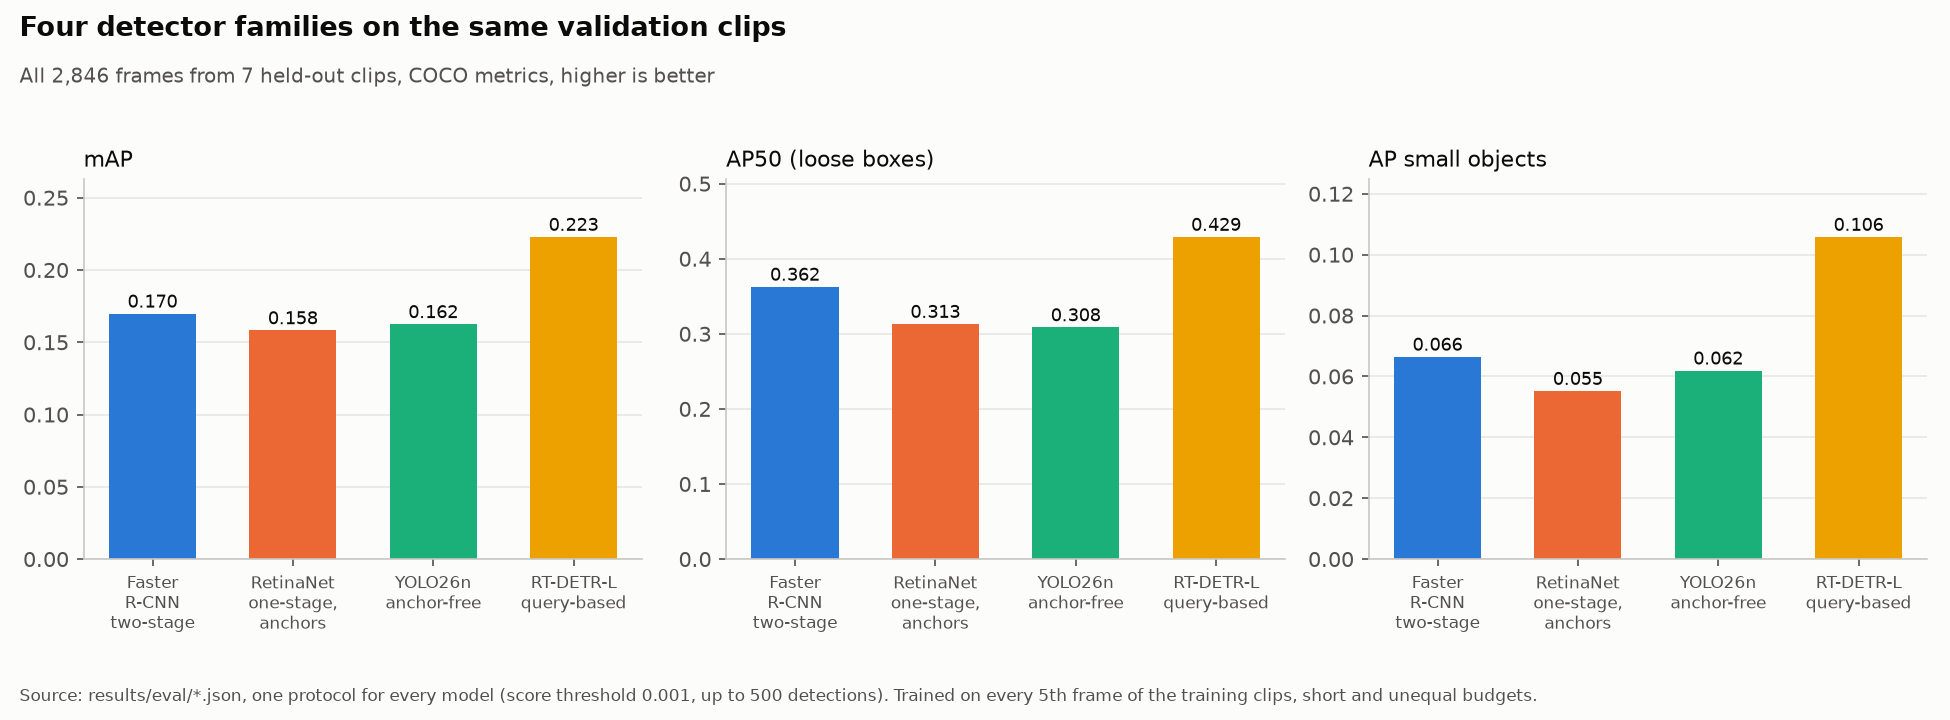

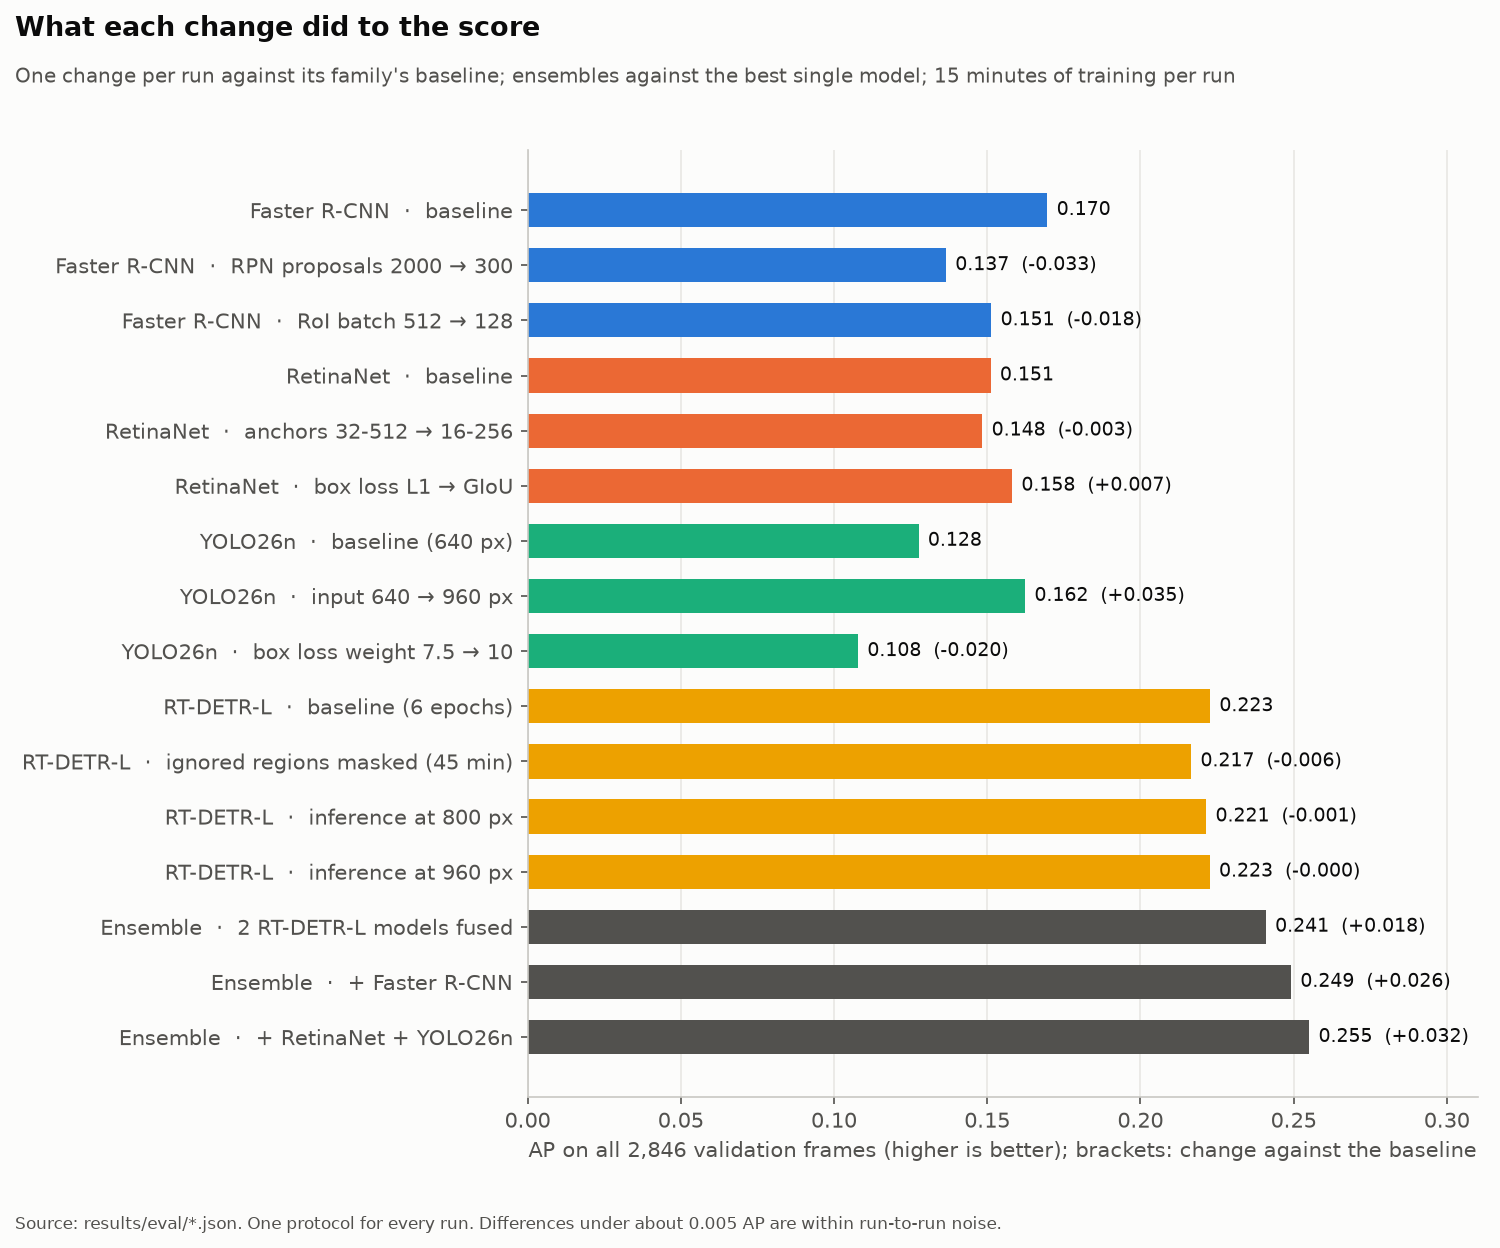

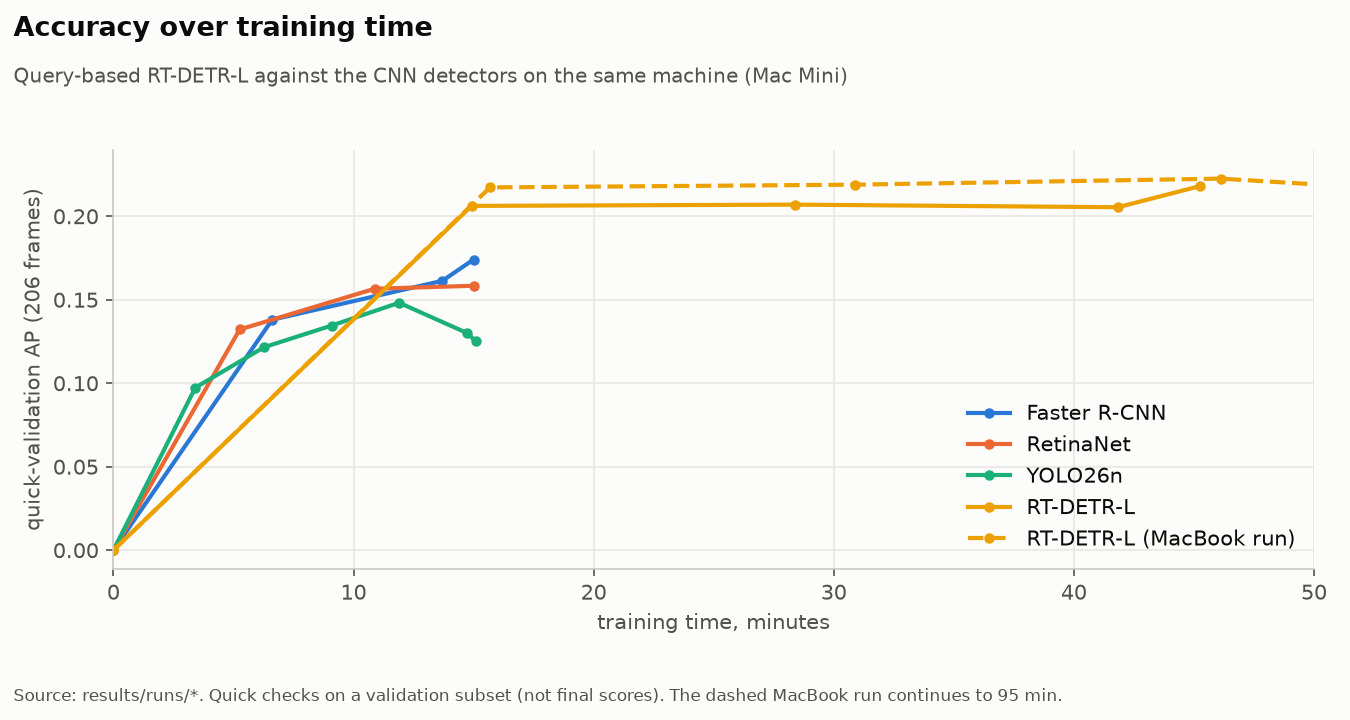

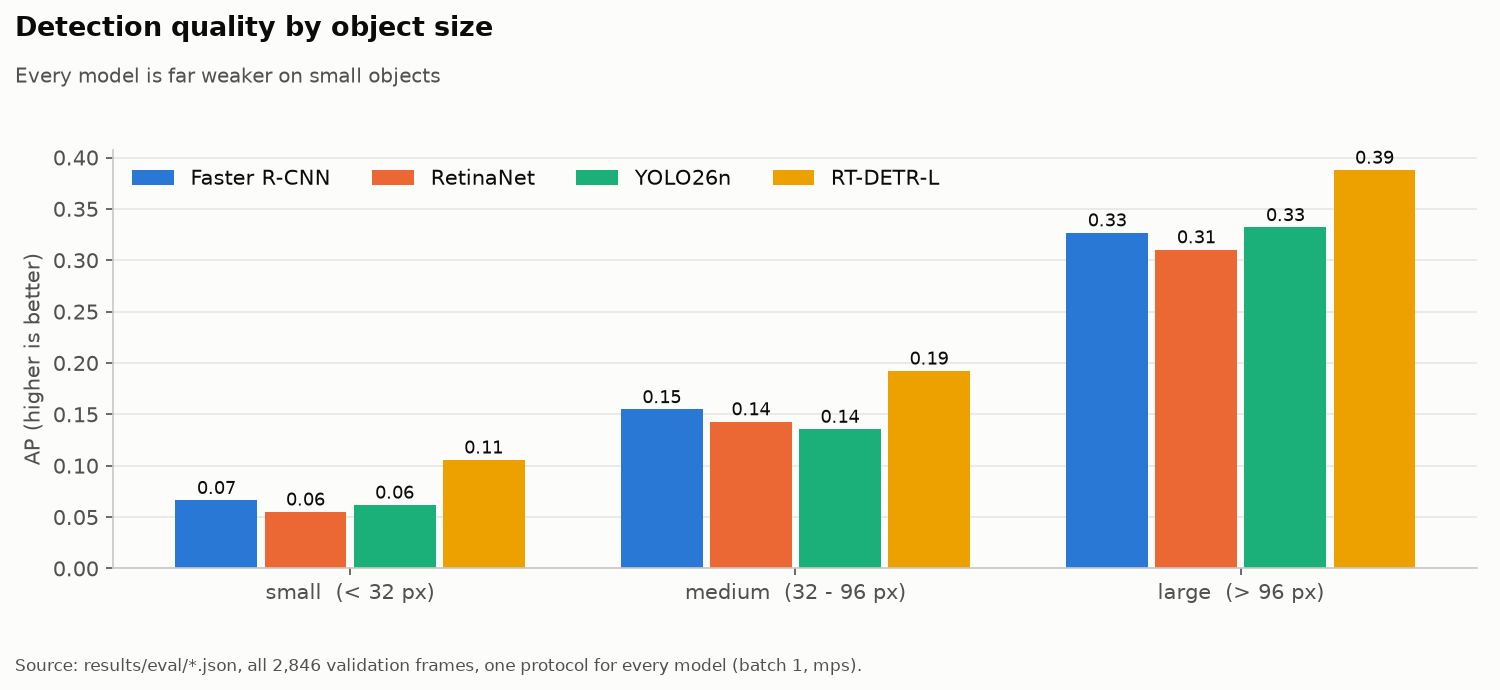

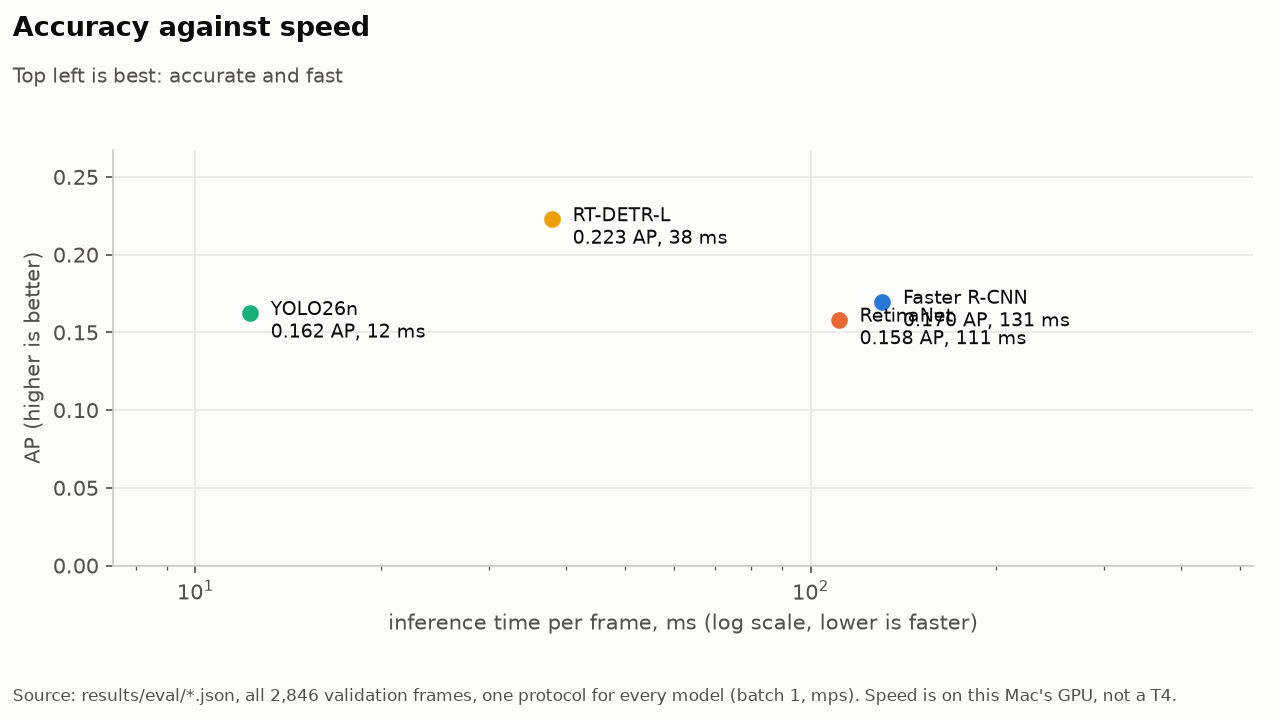

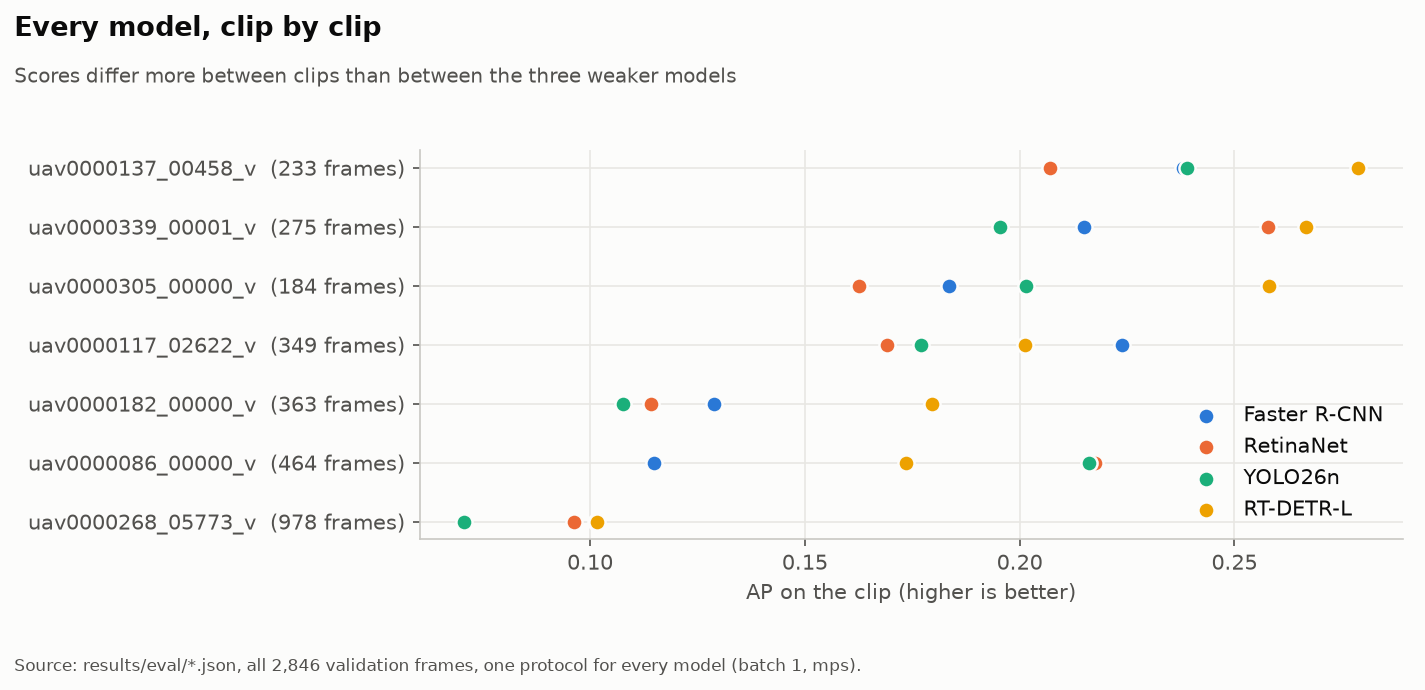

In [3]:
show("fig_model_comparison.png", 1000)
show("fig_tuning.png", 1000)
show("fig_equal_budget.png", 800)
show("fig_eval_by_size.png", 800)
show("fig_eval_speed_accuracy.png", 700)
show("fig_eval_per_clip.png", 800)

## Where the models fail

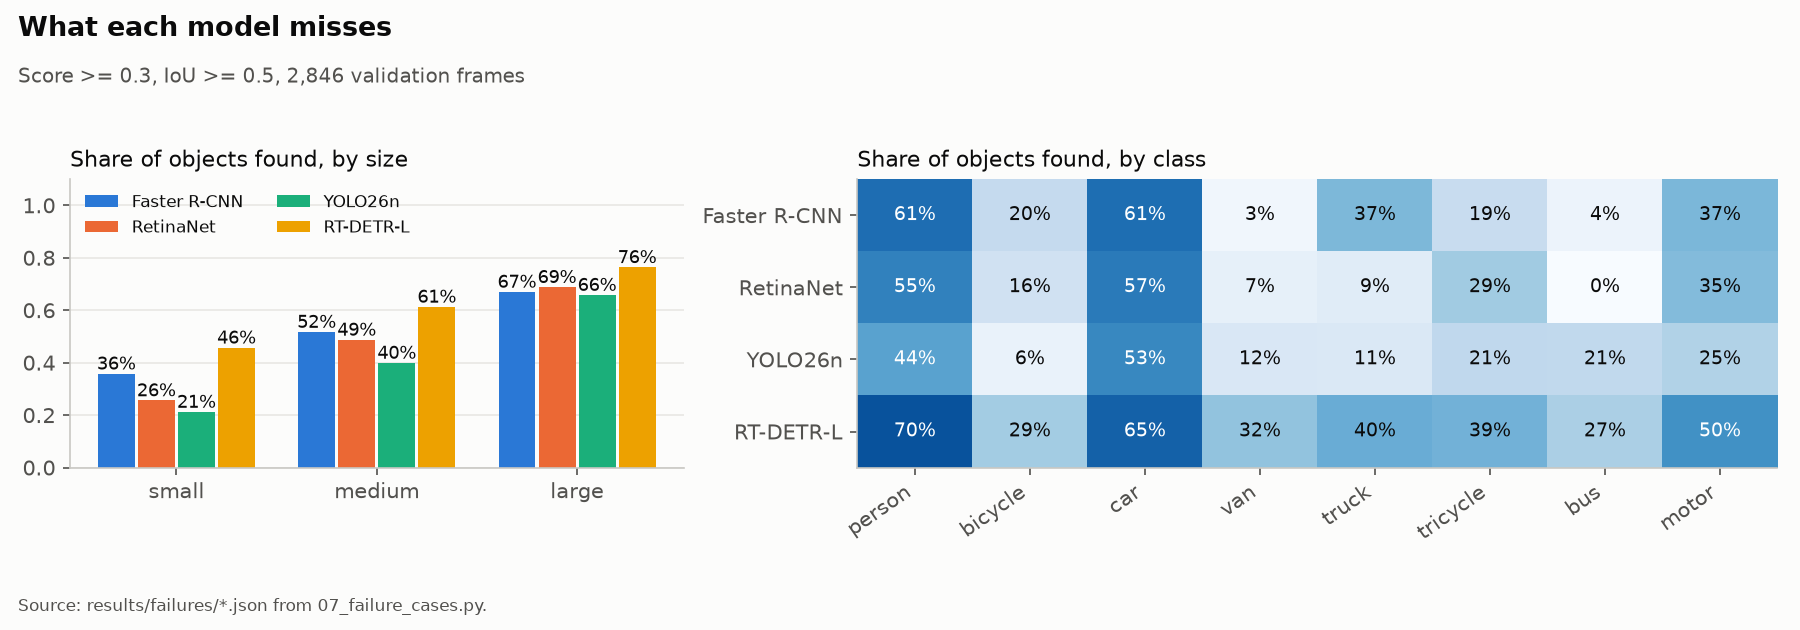

In [4]:
show("fig_failure_compare.png", 1000)

## Submission

The file is produced by `scripts/06_predict_submit.py`, which also validates it. Uploads are recorded in `SUBMISSIONS.md`.

In [5]:
print((ROOT / "SUBMISSIONS.md").read_text())

# Kaggle submissions

Log every upload here. Choose the two final submissions by validation score, not only the public leaderboard.

| Date | File | Model / checkpoint | Validation AP (full val) | Public LB | Notes |
|---|---|---|---:|---:|---|
| | | | | | nothing submitted yet |

Before uploading, run `python scripts/06_predict_submit.py --validate-only submissions/<file>.csv`.
The old RT-DETR-L candidate (`rtdetr_l_best_validated.csv`, validation AP 0.2244) passes that check; the raw `rtdetr_l_best.csv` does not (zero-size boxes).

